# Practice 4 – Multivariate Time Series Forecasting (Electricity Load + Weather)
**Bài toán:** Sử dụng lịch sử 24 giờ gần nhất của 4 biến $X_t = [load_t, temp_t, humidity_t, wind_t]$ để dự báo điện năng tiêu thụ ở bước tiếp theo:
$$X_{t-24:t} \Longrightarrow load_{t+1}$$
**Mô hình so sánh:** **VAR** (Thống kê) vs **XGBoost** (Machine Learning) vs **LSTM** (Deep Learning) — Đánh giá qua **RMSE, MAE, MAPE**.

## 1. Thiết lập môi trường & Import thư viện

In [1]:
import os
os.environ['MPLCONFIGDIR'] = '/tmp/matplotlib'

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler
from statsmodels.tsa.api import VAR
from statsmodels.tsa.stattools import adfuller
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error

warnings.filterwarnings('ignore')
np.random.seed(42)
torch.manual_seed(42)

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 11
print("Đã tải thư viện thành công!")

Đã tải thư viện thành công!


## 2. Nạp & Kiểm tra Dữ liệu (Data Check)
- Các trường dữ liệu: `load` (kW), `temperature` (°C), `humidity` (%), `wind_speed` (m/s).
- Kiểm tra Missing values, kiểu dữ liệu và thống kê mô tả (Outliers / Min - Max - Quartiles).

In [2]:
df = pd.read_csv('../data/raw/electricity_weather_hourly.csv', index_col='Datetime', parse_dates=True)

print(f"Kích thước dữ liệu : {df.shape[0]:,} dòng x {df.shape[1]} cột ({df.index.min()} -> {df.index.max()})")
print(f"Missing values (NaN): {df.isnull().sum().to_dict()}")

display(df.describe().round(2))
display(df.head(3))

Kích thước dữ liệu : 8,736 dòng x 4 cột (2017-01-01 00:00:00 -> 2017-12-30 23:00:00)
Missing values (NaN): {'load': 0, 'temperature': 0, 'humidity': 0, 'wind_speed': 0}


,load,temperature,humidity,wind_speed
count,8736.00,8736.00,8736.00,8736.00
mean,32344.97,18.81,68.26,1.96
std,7068.92,5.81,15.48,2.34
min,14329.11,3.60,12.71,0.05
25%,26292.95,14.40,58.32,0.08
50%,32342.30,18.76,69.82,0.09
75%,37318.00,22.87,81.35,4.92
max,51844.26,39.70,94.75,5.93


,load,temperature,humidity,wind_speed
Datetime,,,,
2017-01-01 00:00:00,29197.974683,6.196833,75.066667,0.081833
2017-01-01 01:00:00,24657.215190,5.548833,77.583333,0.082000
2017-01-01 02:00:00,22083.037973,5.054333,78.933333,0.082333


## 3. Khám phá & Trực quan hóa Dữ liệu (Data Understanding & EDA)
1. Biểu đồ `load` theo thời gian & tính chu kỳ (Seasonality: chu kỳ ngày 24h, chu kỳ tuần 168h).
2. Biểu đồ `load vs temperature` (quan hệ phi tuyến dạng chữ U).
3. Ma trận tương quan (`correlation matrix`).

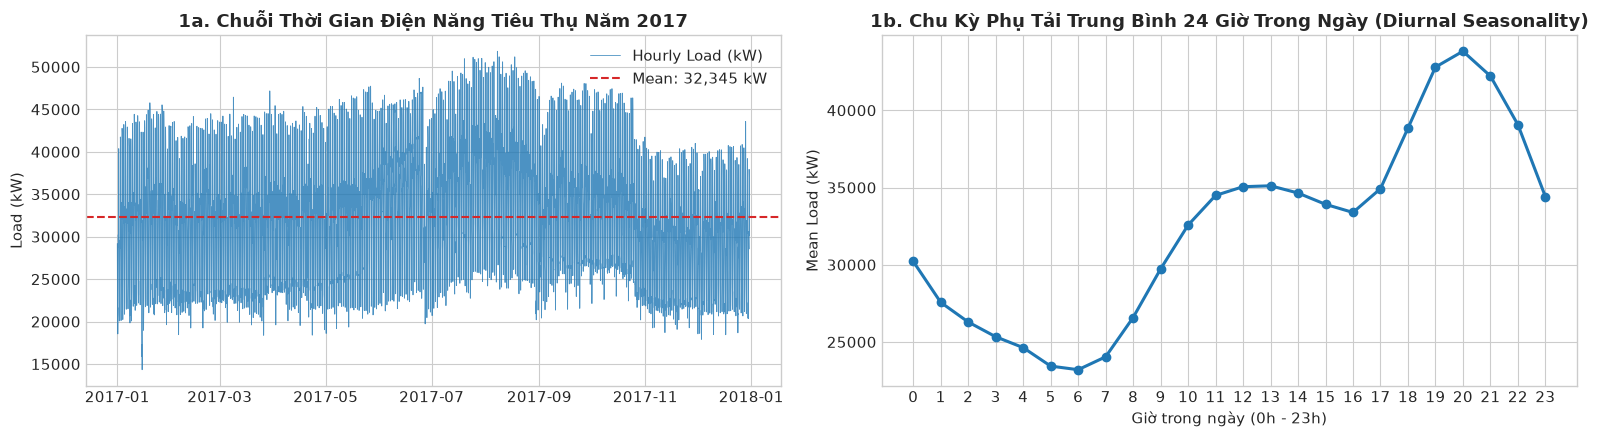

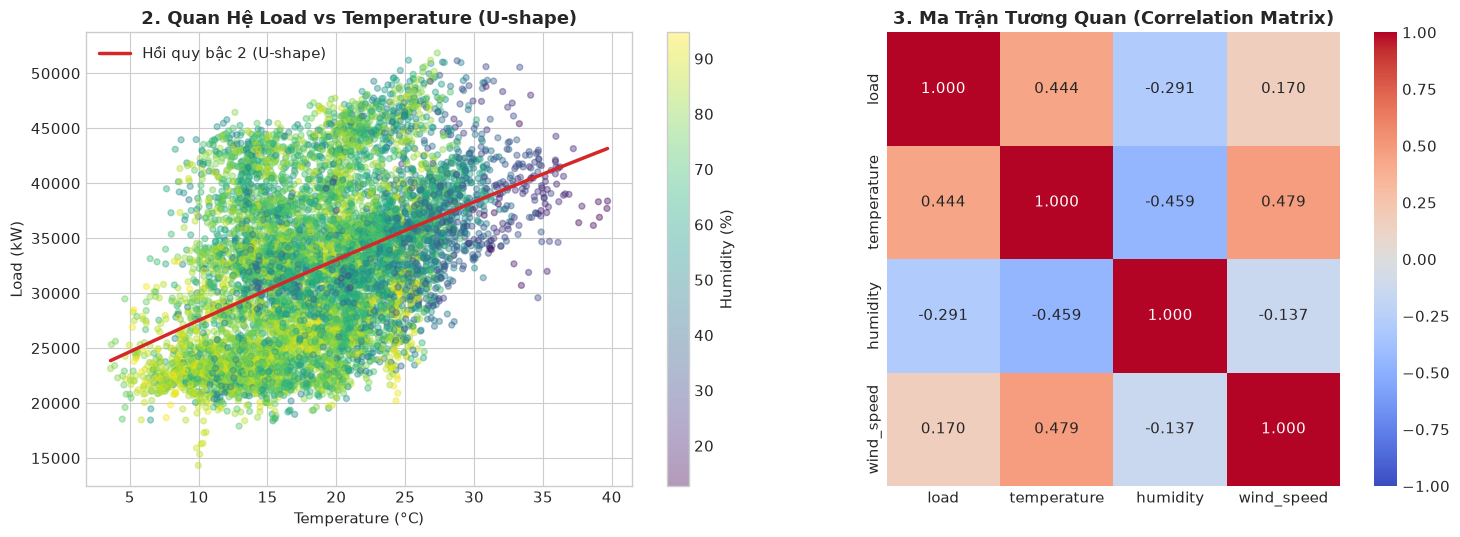

In [3]:
# 1. Biểu đồ Load toàn năm & Chu kỳ Ngày (24h) / Tuần (168h)
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))

axes[0].plot(df.index, df['load'], color='#1f77b4', lw=0.6, alpha=0.8, label='Hourly Load (kW)')
axes[0].axhline(df['load'].mean(), color='#d62728', linestyle='--', lw=1.5, label=f"Mean: {df['load'].mean():,.0f} kW")
axes[0].set_title('1a. Chuỗi Thời Gian Điện Năng Tiêu Thụ Năm 2017', fontweight='bold')
axes[0].set_ylabel('Load (kW)')
axes[0].legend(loc='upper right')

hourly_mean = df.groupby(df.index.hour)['load'].mean()
axes[1].plot(hourly_mean.index, hourly_mean.values, color='#1f77b4', marker='o', lw=2.2)
axes[1].set_xticks(range(0, 24))
axes[1].set_title('1b. Chu Kỳ Phụ Tải Trung Bình 24 Giờ Trong Ngày (Diurnal Seasonality)', fontweight='bold')
axes[1].set_xlabel('Giờ trong ngày (0h - 23h)')
axes[1].set_ylabel('Mean Load (kW)')

plt.tight_layout()
plt.show()

# 2. Biểu đồ Load vs Temperature & 3. Ma trận tương quan
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

sc = axes[0].scatter(df['temperature'], df['load'], c=df['humidity'], cmap='viridis', alpha=0.4, s=18)
plt.colorbar(sc, ax=axes[0], label='Humidity (%)')
z = np.polyfit(df['temperature'], df['load'], 2)
p = np.poly1d(z)
t_rng = np.linspace(df['temperature'].min(), df['temperature'].max(), 200)
axes[0].plot(t_rng, p(t_rng), color='#d62728', lw=2.5, label='Hồi quy bậc 2 (U-shape)')
axes[0].set_title('2. Quan Hệ Load vs Temperature (U-shape)', fontweight='bold')
axes[0].set_xlabel('Temperature (°C)')
axes[0].set_ylabel('Load (kW)')
axes[0].legend(loc='upper left')

sns.heatmap(df.corr(), annot=True, fmt=".3f", cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True, ax=axes[1])
axes[1].set_title('3. Ma Trận Tương Quan (Correlation Matrix)', fontweight='bold')

plt.tight_layout()
plt.show()

## 4. Tiền xử lý Dữ liệu (Preprocessing)
- Chia tập dữ liệu theo thứ tự thời gian (`shuffle=False`): **Train (70%)**, **Validation (15%)**, **Test (15%)**.
- Chuẩn hóa tất cả các biến bằng `StandardScaler` (chỉ fit trên tập Train).

In [4]:
n_total = len(df)
n_train = int(n_total * 0.70)
n_val = int(n_total * 0.15)

df_train = df.iloc[:n_train].copy()
df_val = df.iloc[n_train : n_train + n_val].copy()
df_test = df.iloc[n_train + n_val :].copy()

print(f"Train (70%) : {len(df_train):,} dòng ({df_train.index.min()} -> {df_train.index.max()})")
print(f"Val   (15%) : {len(df_val):,} dòng ({df_val.index.min()} -> {df_val.index.max()})")
print(f"Test  (15%) : {len(df_test):,} dòng ({df_test.index.min()} -> {df_test.index.max()})")

feature_cols = ['load', 'temperature', 'humidity', 'wind_speed']
scaler = StandardScaler()
scaler.fit(df_train[feature_cols])

df_train_scaled = pd.DataFrame(scaler.transform(df_train[feature_cols]), index=df_train.index, columns=feature_cols)
df_val_scaled = pd.DataFrame(scaler.transform(df_val[feature_cols]), index=df_val.index, columns=feature_cols)
df_test_scaled = pd.DataFrame(scaler.transform(df_test[feature_cols]), index=df_test.index, columns=feature_cols)
df_full_scaled = pd.DataFrame(scaler.transform(df[feature_cols]), index=df.index, columns=feature_cols)

load_mean, load_scale = scaler.mean_[0], scaler.scale_[0]
def inverse_load(y_scaled):
    return y_scaled * load_scale + load_mean

Train (70%) : 6,115 dòng (2017-01-01 00:00:00 -> 2017-09-12 18:00:00)
Val   (15%) : 1,310 dòng (2017-09-12 19:00:00 -> 2017-11-06 08:00:00)
Test  (15%) : 1,311 dòng (2017-11-06 09:00:00 -> 2017-12-30 23:00:00)


## 5. Kỹ nghệ Đặc trưng (Feature Engineering)
- **Cửa sổ trễ ($L = 24$ giờ):** Tạo 24 lags cho mỗi biến $\rightarrow 24 \times 4 = 96$ lag features.
- **Rolling Features (cho XGBoost):** `load_rolling_mean_6h`, `load_rolling_std_24h`, `load_trend` ($load_{t-1} - load_{t-24}$) $\rightarrow$ Tổng cộng **99 features**.
- **Tensor 3D (cho LSTM):** Shape `(batch_samples, 24, 4)`.

In [5]:
def make_xgb_dataset(df_s, lag_w=24):
    df_f = pd.DataFrame(index=df_s.index)
    for col in feature_cols:
        for lag in range(1, lag_w + 1):
            df_f[f"{col}_lag_{lag}"] = df_s[col].shift(lag)
    target_sh = df_s['load'].shift(1)
    df_f['load_rolling_mean_6h'] = target_sh.rolling(6).mean()
    df_f['load_rolling_std_24h'] = target_sh.rolling(24).std()
    df_f['load_trend'] = target_sh - df_s['load'].shift(lag_w)
    valid_idx = df_f.dropna().index
    return df_f.loc[valid_idx], df_s.loc[valid_idx, 'load']

X_train_xgb, y_train_xgb = make_xgb_dataset(df_train_scaled)
X_val_xgb, y_val_xgb = make_xgb_dataset(df_val_scaled)
X_test_xgb, y_test_xgb = make_xgb_dataset(df_test_scaled)

def make_lstm_dataset(df_s, lag_w=24):
    mat = df_s[feature_cols].values
    num_samples = len(mat) - lag_w
    X = np.zeros((num_samples, lag_w, len(feature_cols)), dtype=np.float32)
    y = np.zeros((num_samples,), dtype=np.float32)
    for i in range(num_samples):
        X[i] = mat[i : i + lag_w]
        y[i] = mat[i + lag_w, 0]
    return X, y, df_s.index[lag_w:]

X_train_lstm, y_train_lstm, _ = make_lstm_dataset(df_train_scaled)
X_val_lstm, y_val_lstm, _ = make_lstm_dataset(df_val_scaled)
X_test_lstm, y_test_lstm, test_timestamps = make_lstm_dataset(df_test_scaled)
y_true_orig = inverse_load(y_test_lstm)

print(f"XGBoost 2D Input (Train / Val / Test): {X_train_xgb.shape} / {X_val_xgb.shape} / {X_test_xgb.shape}")
print(f"LSTM 3D Tensor   (Train / Val / Test): {X_train_lstm.shape} / {X_val_lstm.shape} / {X_test_lstm.shape}")

XGBoost 2D Input (Train / Val / Test): (6091, 99) / (1286, 99) / (1287, 99)
LSTM 3D Tensor   (Train / Val / Test): (6091, 24, 4) / (1286, 24, 4) / (1287, 24, 4)


## 6. Mô hình 1 – VAR (Statistical Baseline)
1. Kiểm tra tính dừng bằng **ADF Test** (nếu không dừng $\rightarrow$ lấy sai phân bậc 1 `d=1`).
2. Chọn bậc trễ tối ưu $p$ dựa trên **AIC / BIC**.
3. Huấn luyện VAR và dự báo Walk-forward trên tập Test.

,Variable,ADF (d=0),p-val (d=0),Status (d=0),ADF (d=1),p-val (d=1),Status (d=1)
0,load,-4.827,4.82e-05,Dừng,-17.755,3.36e-30,Dừng
1,temperature,-2.474,1.22e-01,Không dừng,-19.301,0.00e+00,Dừng
2,humidity,-8.388,2.40e-13,Dừng,-15.875,8.88e-29,Dừng
3,wind_speed,-5.401,3.38e-06,Dừng,-17.426,4.80e-30,Dừng


-> Áp dụng sai phân d=1. Bậc trễ tối ưu theo AIC: p = 24


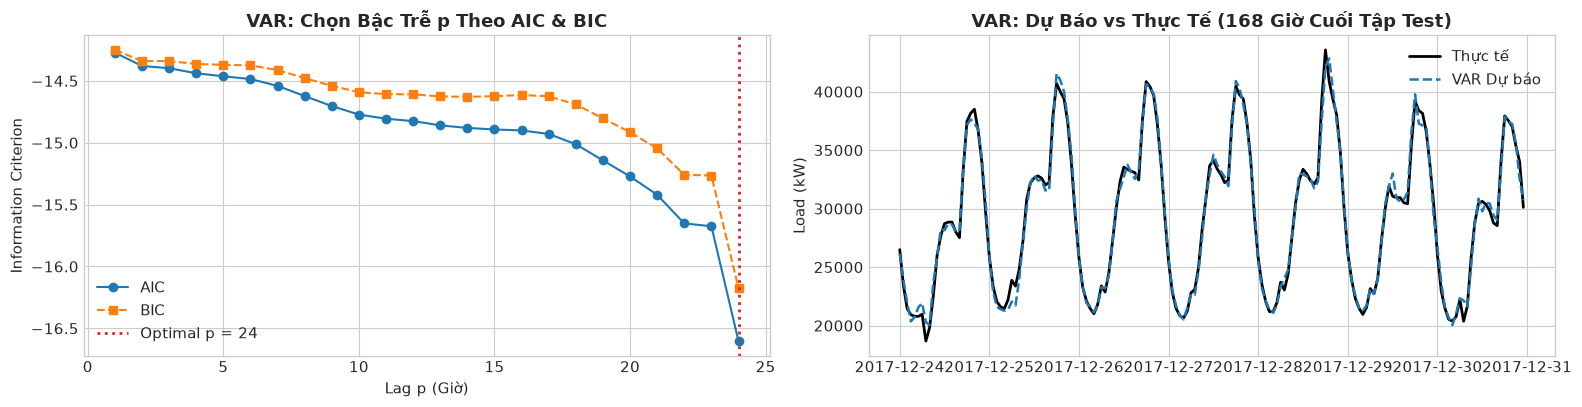

In [6]:
adf_rows = []
all_stationary = True
for col in feature_cols:
    r0 = adfuller(df_train_scaled[col].dropna())
    stat0 = (r0[1] < 0.05)
    if not stat0:
        all_stationary = False
    r1 = adfuller(df_train_scaled[col].diff().dropna())
    adf_rows.append({
        'Variable': col,
        'ADF (d=0)': round(r0[0], 3), 'p-val (d=0)': f"{r0[1]:.2e}", 'Status (d=0)': 'Dừng' if stat0 else 'Không dừng',
        'ADF (d=1)': round(r1[0], 3), 'p-val (d=1)': f"{r1[1]:.2e}", 'Status (d=1)': 'Dừng'
    })
display(pd.DataFrame(adf_rows))

var_data = df_train_scaled.diff().dropna() if not all_stationary else df_train_scaled.copy()
var_model = VAR(var_data)
lag_sel = var_model.select_order(maxlags=24)
optimal_p = max(1, int(lag_sel.aic))
var_fitted = var_model.fit(optimal_p)
print(f"-> Áp dụng sai phân d=1. Bậc trễ tối ưu theo AIC: p = {optimal_p}")

# Walk-forward forecast trên tập Test
start_pos = df_full_scaled.index.get_loc(test_timestamps[0])
data_mat = df_full_scaled.values
pred_var_scaled = []
for pos in range(start_pos, len(df_full_scaled)):
    hist_diff = np.diff(data_mat[pos - optimal_p - 1 : pos], axis=0)
    diff_pred = var_fitted.forecast(y=hist_diff[-optimal_p:], steps=1)[0]
    pred_var_scaled.append(data_mat[pos - 1, 0] + diff_pred[0])

pred_var_orig = inverse_load(np.array(pred_var_scaled))

# Biểu đồ quá trình của Mô hình 1 (VAR): Chọn lag AIC/BIC & Dự báo 168h
fig, axes = plt.subplots(1, 2, figsize=(16, 4.2))
lags_r = range(1, 25)
axes[0].plot(lags_r, [lag_sel.ics['aic'][i] for i in lags_r], marker='o', label='AIC', color='#1f77b4')
axes[0].plot(lags_r, [lag_sel.ics['bic'][i] for i in lags_r], marker='s', linestyle='--', label='BIC', color='#ff7f0e')
axes[0].axvline(optimal_p, color='#d62728', linestyle=':', lw=2, label=f'Optimal p = {optimal_p}')
axes[0].set_title('VAR: Chọn Bậc Trễ p Theo AIC & BIC', fontweight='bold')
axes[0].set_xlabel('Lag p (Giờ)')
axes[0].set_ylabel('Information Criterion')
axes[0].legend()

sub_slice = slice(-168, None)
axes[1].plot(test_timestamps[sub_slice], y_true_orig[sub_slice], color='black', lw=2, label='Thực tế')
axes[1].plot(test_timestamps[sub_slice], pred_var_orig[sub_slice], color='#1f77b4', linestyle='--', lw=1.8, label='VAR Dự báo')
axes[1].set_title('VAR: Dự Báo vs Thực Tế (168 Giờ Cuối Tập Test)', fontweight='bold')
axes[1].set_ylabel('Load (kW)')
axes[1].legend()

plt.tight_layout()
plt.show()

## 7. Mô hình 2 – XGBoost (Machine Learning)
- Đầu vào: Vector phẳng 99 đặc trưng (`96 lags + 3 rolling/trend features`).
- Huấn luyện với `max_depth=6`, `n_estimators=300` và **Early Stopping** trên tập Validation.

XGBoost dừng sớm (Early Stopping) tại Best Iteration = 252 (Val Scaled RMSE = 0.1316)


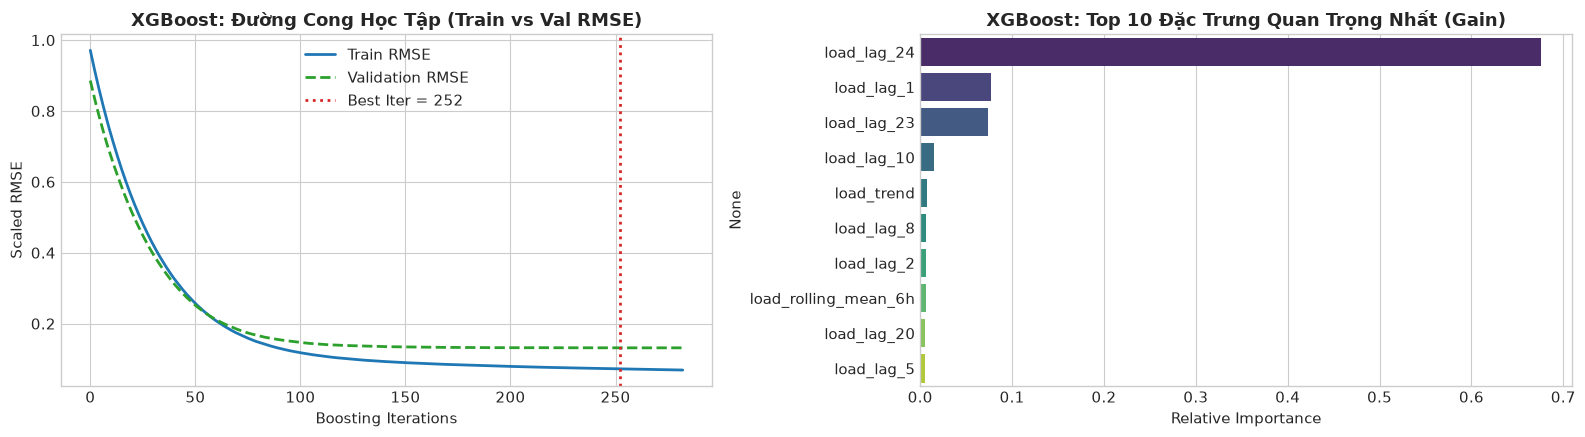

In [7]:
xgb_model = XGBRegressor(
    n_estimators=300, learning_rate=0.03, max_depth=6,
    subsample=0.8, colsample_bytree=0.8,
    early_stopping_rounds=30, eval_metric='rmse',
    random_state=42, n_jobs=-1
)

xgb_model.fit(
    X_train_xgb, y_train_xgb,
    eval_set=[(X_train_xgb, y_train_xgb), (X_val_xgb, y_val_xgb)],
    verbose=False
)

evals_res = xgb_model.evals_result()
xgb_train_curve = evals_res['validation_0']['rmse']
xgb_val_curve = evals_res['validation_1']['rmse']
best_iter = xgb_model.best_iteration
print(f"XGBoost dừng sớm (Early Stopping) tại Best Iteration = {best_iter} (Val Scaled RMSE = {xgb_val_curve[best_iter]:.4f})")

pred_xgb_orig = inverse_load(xgb_model.predict(X_test_xgb.loc[test_timestamps]))

# Biểu đồ quá trình của Mô hình 2 (XGBoost): Learning Curve & Top 10 Feature Importance
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))

axes[0].plot(xgb_train_curve, label='Train RMSE', color='#1f77b4', lw=2)
axes[0].plot(xgb_val_curve, label='Validation RMSE', color='#2ca02c', linestyle='--', lw=2)
axes[0].axvline(best_iter, color='#d62728', linestyle=':', lw=2, label=f'Best Iter = {best_iter}')
axes[0].set_title('XGBoost: Đường Cong Học Tập (Train vs Val RMSE)', fontweight='bold')
axes[0].set_xlabel('Boosting Iterations')
axes[0].set_ylabel('Scaled RMSE')
axes[0].legend()

feat_imp = pd.Series(xgb_model.feature_importances_, index=X_train_xgb.columns).sort_values(ascending=False)
sns.barplot(x=feat_imp.head(10).values, y=feat_imp.head(10).index, palette='viridis', ax=axes[1])
axes[1].set_title('XGBoost: Top 10 Đặc Trưng Quan Trọng Nhất (Gain)', fontweight='bold')
axes[1].set_xlabel('Relative Importance')

plt.tight_layout()
plt.show()

## 8. Mô hình 3 – LSTM (Deep Learning)
- Đầu vào: Tensor 3D `(batch_samples, 24, 4)`.
- Kiến trúc mạng: $\text{LSTM}(64) \rightarrow \text{LSTM}(32) \rightarrow \text{Dense}(1)$ với hàm mất mát **MSE**, tối ưu **Adam** và **Early Stopping**.

LSTM Early Stopping tại Epoch 44 (Best Epoch = 34, Best Val MSE = 0.0225)


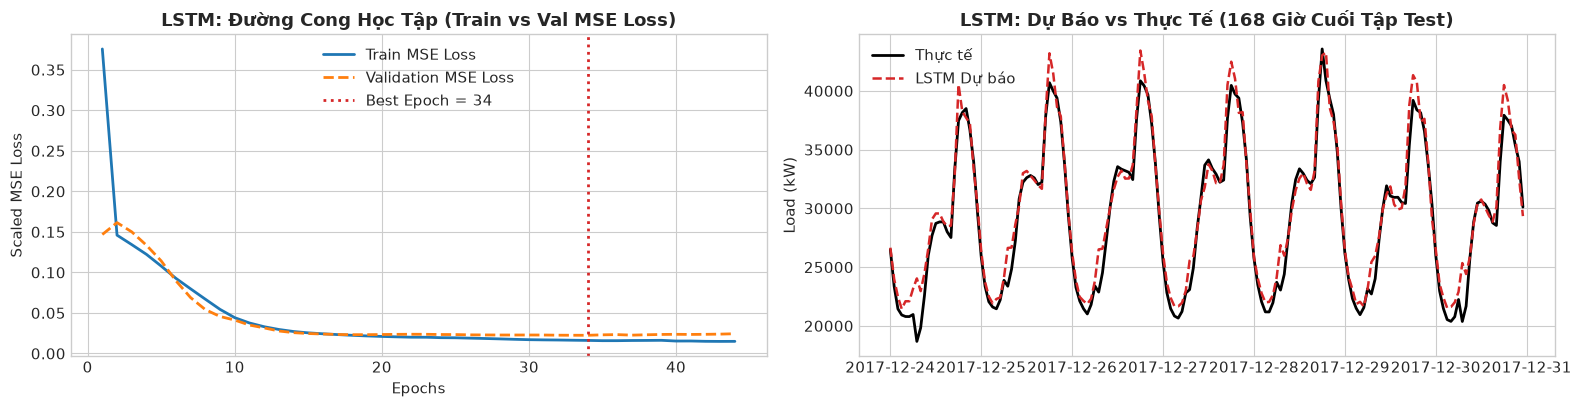

In [8]:
class LSTMModel(nn.Module):
    def __init__(self, input_dim=4, h1=64, h2=32, out_dim=1):
        super().__init__()
        self.lstm1 = nn.LSTM(input_dim, h1, batch_first=True)
        self.lstm2 = nn.LSTM(h1, h2, batch_first=True)
        self.fc = nn.Linear(h2, out_dim)

    def forward(self, x):
        out1, _ = self.lstm1(x)
        out2, _ = self.lstm2(out1)
        return self.fc(out2[:, -1, :]).squeeze(-1)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.manual_seed(42)
lstm_net = LSTMModel().to(device)

train_loader = DataLoader(TensorDataset(torch.from_numpy(X_train_lstm), torch.from_numpy(y_train_lstm)), batch_size=32, shuffle=False)
val_loader = DataLoader(TensorDataset(torch.from_numpy(X_val_lstm), torch.from_numpy(y_val_lstm)), batch_size=32, shuffle=False)

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(lstm_net.parameters(), lr=0.001)

train_losses, val_losses = [], []
best_loss, best_epoch, patience, patience_cnt, best_weights = float('inf'), 1, 10, 0, None

for epoch in range(1, 51):
    lstm_net.train()
    t_loss = sum(
        (optimizer.zero_grad(),
         loss := criterion(lstm_net(bx.to(device)), by.to(device)),
         loss.backward(),
         optimizer.step(),
         loss.item() * len(bx))[4]
        for bx, by in train_loader
    )
    train_losses.append(t_loss / len(X_train_lstm))

    lstm_net.eval()
    with torch.no_grad():
        v_loss = sum(criterion(lstm_net(vx.to(device)), vy.to(device)).item() * len(vx) for vx, vy in val_loader)
    avg_v = v_loss / len(X_val_lstm)
    val_losses.append(avg_v)

    if avg_v < best_loss:
        best_loss, best_epoch, patience_cnt = avg_v, epoch, 0
        best_weights = {k: v.cpu().clone() for k, v in lstm_net.state_dict().items()}
    else:
        patience_cnt += 1
        if patience_cnt >= patience:
            print(f"LSTM Early Stopping tại Epoch {epoch} (Best Epoch = {best_epoch}, Best Val MSE = {best_loss:.4f})")
            break

lstm_net.load_state_dict(best_weights)
lstm_net.eval()
with torch.no_grad():
    pred_lstm_scaled = lstm_net(torch.from_numpy(X_test_lstm).to(device)).cpu().numpy()
pred_lstm_orig = inverse_load(pred_lstm_scaled)

# Biểu đồ quá trình của Mô hình 3 (LSTM): Loss Curve & Dự báo 168h
fig, axes = plt.subplots(1, 2, figsize=(16, 4.2))
axes[0].plot(range(1, len(train_losses) + 1), train_losses, label='Train MSE Loss', color='#1f77b4', lw=2)
axes[0].plot(range(1, len(val_losses) + 1), val_losses, label='Validation MSE Loss', color='#ff7f0e', linestyle='--', lw=2)
axes[0].axvline(best_epoch, color='#d62728', linestyle=':', lw=2, label=f'Best Epoch = {best_epoch}')
axes[0].set_title('LSTM: Đường Cong Học Tập (Train vs Val MSE Loss)', fontweight='bold')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Scaled MSE Loss')
axes[0].legend()

axes[1].plot(test_timestamps[sub_slice], y_true_orig[sub_slice], color='black', lw=2, label='Thực tế')
axes[1].plot(test_timestamps[sub_slice], pred_lstm_orig[sub_slice], color='#d62728', linestyle='--', lw=1.8, label='LSTM Dự báo')
axes[1].set_title('LSTM: Dự Báo vs Thực Tế (168 Giờ Cuối Tập Test)', fontweight='bold')
axes[1].set_ylabel('Load (kW)')
axes[1].legend()

plt.tight_layout()
plt.show()

## 9. Đánh giá & So sánh 3 Mô hình (RMSE, MAE, MAPE)

,Model,RMSE (kW),MAE (kW),MAPE (%)
0,VAR (Statistical),641.15,443.01,1.57
1,XGBoost (ML),970.12,683.33,2.40
2,LSTM (Deep Learning),1305.30,926.27,3.44


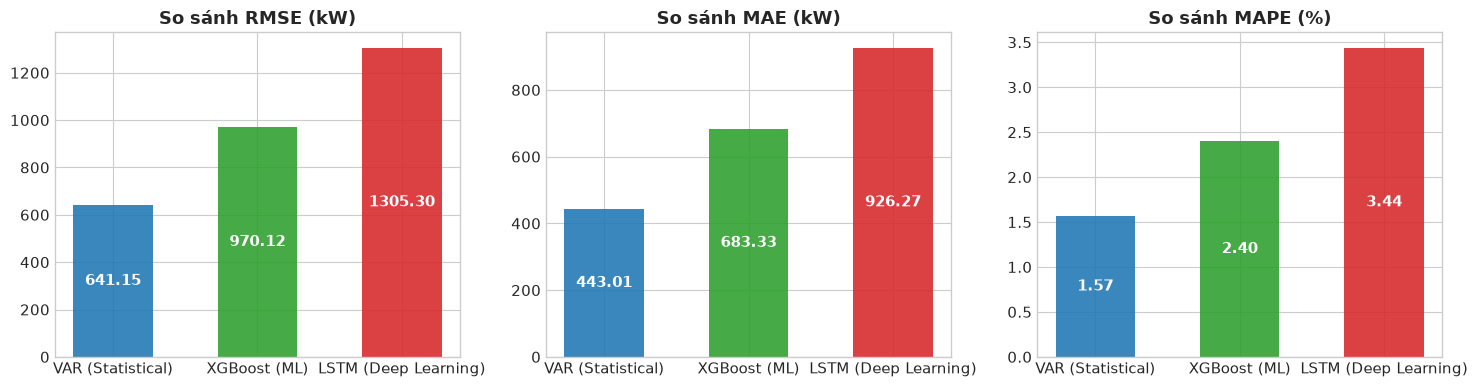

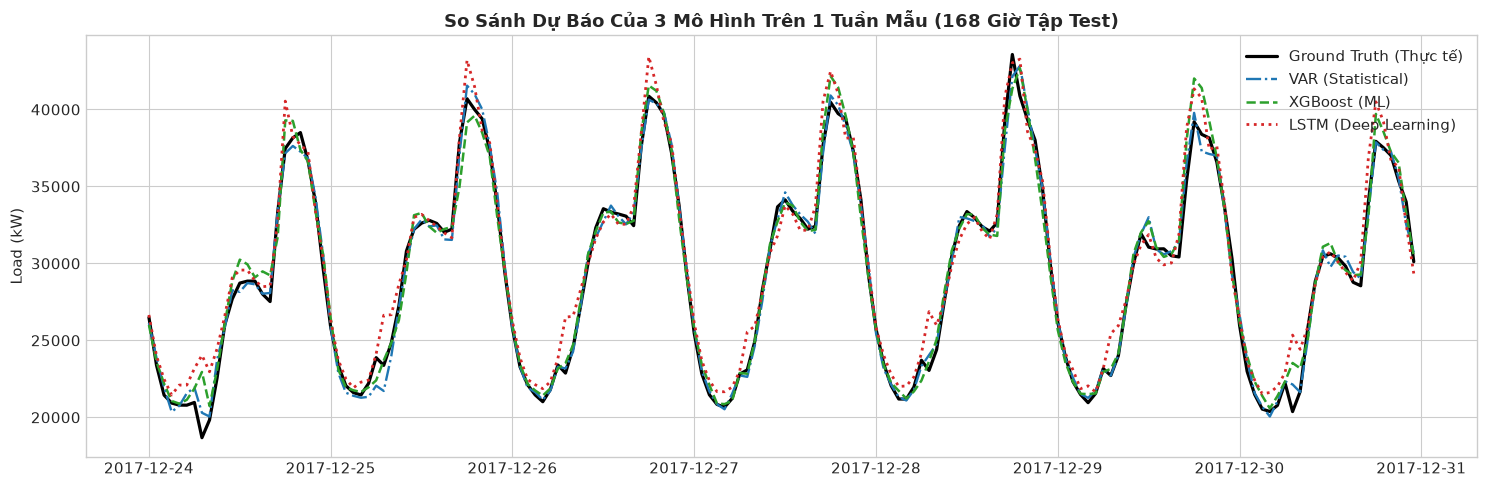

In [9]:
models_preds = {
    'VAR (Statistical)': pred_var_orig,
    'XGBoost (ML)': pred_xgb_orig,
    'LSTM (Deep Learning)': pred_lstm_orig
}

bench_results = []
for name, p_orig in models_preds.items():
    bench_results.append({
        'Model': name,
        'RMSE (kW)': np.sqrt(mean_squared_error(y_true_orig, p_orig)),
        'MAE (kW)': mean_absolute_error(y_true_orig, p_orig),
        'MAPE (%)': mean_absolute_percentage_error(y_true_orig, p_orig) * 100
    })

df_benchmark = pd.DataFrame(bench_results)
display(df_benchmark.round(2))

# 1. Bar chart so sánh RMSE, MAE, MAPE
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
metrics = ['RMSE (kW)', 'MAE (kW)', 'MAPE (%)']
colors = ['#1f77b4', '#2ca02c', '#d62728']

for i, m in enumerate(metrics):
    bars = axes[i].bar(df_benchmark['Model'], df_benchmark[m], color=colors, alpha=0.88, width=0.55)
    axes[i].set_title(f'So sánh {m}', fontweight='bold')
    for bar in bars:
        axes[i].annotate(f"{bar.get_height():.2f}",
                         (bar.get_x() + bar.get_width() / 2., bar.get_height() * 0.5),
                         ha='center', va='center', color='white', fontweight='bold')
plt.tight_layout()
plt.show()

# 2. So sánh đường dự báo của cả 3 mô hình trên 1 tuần mẫu (168 giờ)
fig, ax = plt.subplots(figsize=(15, 5))
t_sample = test_timestamps[sub_slice]
ax.plot(t_sample, y_true_orig[sub_slice], label='Ground Truth (Thực tế)', color='black', lw=2.3)
ax.plot(t_sample, pred_var_orig[sub_slice], label='VAR (Statistical)', color='#1f77b4', linestyle='-.', lw=1.7)
ax.plot(t_sample, pred_xgb_orig[sub_slice], label='XGBoost (ML)', color='#2ca02c', linestyle='--', lw=1.8)
ax.plot(t_sample, pred_lstm_orig[sub_slice], label='LSTM (Deep Learning)', color='#d62728', linestyle=':', lw=2.0)
ax.set_title('So Sánh Dự Báo Của 3 Mô Hình Trên 1 Tuần Mẫu (168 Giờ Tập Test)', fontweight='bold')
ax.set_ylabel('Load (kW)')
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

## 10. Tóm tắt Trả lời 6 Câu hỏi Phân tích & Bài tập Nâng cao

1. **Biến thời tiết nào ảnh hưởng mạnh nhất đến điện năng?**
   - **Nhiệt độ (`temperature`)** ($r = +0.444$) với mối quan hệ **phi tuyến chữ U**: phụ tải thấp nhất ở $14^\circ\text{C} - 18^\circ\text{C}$ và tăng vọt khi trời nóng $>25^\circ\text{C}$ (bật điều hòa làm mát).
2. **Khi nào VAR thất bại?**
   - Khi quan hệ giữa các biến là **phi tuyến phức tạp**, khi số lượng biến lớn gây **bùng nổ tham số** ($K^2 \cdot p$), hoặc khi chuỗi **không dừng** mà sai phân không khử được.
3. **XGBoost học được thông tin gì từ thời tiết?**
   - Học được các **ngưỡng kích hoạt nhiệt độ (Threshold split points)** và **tương tác chéo đa biến** (Nhiệt độ + Độ ẩm cao $\rightarrow$ chỉ số oi bức Heat Index).
4. **LSTM học được chu kỳ nào (ngày, tuần)?**
   - Học trực tiếp **chu kỳ ngày-đêm 24h (Diurnal cycle)** từ cửa sổ Tensor $(N, 24, 4)$ và nhận diện mức nền chu kỳ tuần qua trạng thái bộ nhớ $c_t, h_t$.
5. **LSTM có bị overfitting không?**
   - **Không**, nhờ kiến trúc gọn ($64 \rightarrow 32 \rightarrow 1$) và **Early Stopping** (Val Loss giảm đồng pha và bám sát Train Loss).
6. **Sự khác biệt giữa Machine Learning (XGBoost) và Deep Learning (LSTM)?**
   - **XGBoost:** Cần làm phẳng chuỗi thành vector 2D (96 lags) + tạo đặc trưng thủ công (`rolling_mean`, `std`, `trend`), huấn luyện nhanh, giải thích được Feature Importance.
   - **LSTM:** Nhận trực tiếp Tensor 3D `(batch, 24, 4)` bảo toàn thứ tự thời gian, tự học biểu diễn qua cổng nhớ nhưng tốn tài nguyên hơn và mang tính hộp đen.

---
### Bài tập nâng cao – Traffic Forecasting (`METR-LA` / `PEMS-BAY` - DCRNN)
- **Bài toán:** Dự báo tốc độ xe tại 207 trạm cảm biến: $[X_{t-12}, \dots, X_t] \Longrightarrow X_{t+3}, X_{t+6}, X_{t+12}$ ($15, 30, 60$ phút tới).
- **Giải pháp DCRNN:** Kết hợp **Diffusion Graph Convolution** (mô hình hóa phụ thuộc không gian xuôi/ngược dòng xe trên đồ thị mạng lưới đường) và **GRU Seq2Seq + Scheduled Sampling** (mô hình hóa phụ thuộc thời gian đa bước).